### Model comparison, enhancement and deployment

This notebook loads the cleaned dataset produced by Question 1.

In [51]:
# load data
import json
import re
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay

In [52]:
# load file
path = Path("../data/processed/cleaned_research_abstracts.csv")

df = pd.read_csv(path)

In [53]:
# view file
print(df)

                                         DOI  \
0                       10.1155/2021/1071145   
1                 10.1007/s43546-022-00384-2   
2                           10.1002/for.2667   
3                 10.1007/s42973-021-00091-x   
4                  10.1007/s40258-012-0003-z   
...                                      ...   
1120                      10.1007/bf00123887   
1121  10.1093/acrefore/9780190625979.013.171   
1122                  10.1287/mnsc.2013.1812   
1123                        10.2118/22022-pa   
1124               10.1017/s1365100504030202   

                                               Abstract      Label  \
0     Forward-looking forecasting of the inflation r...         ai   
1     Our study examined the disaggregation of infla...         ai   
2     This paper develops a dynamic factor model tha...  classical   
3     In this paper, I use a simple SIR Macro model ...  classical   
4     BackgroundGame theory is useful for identifyin...  classical   
...

In [54]:
# view dataframe
df.head()

,DOI,Abstract,Label,Clean_Abstract
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai,forward-looking forecasting of the inflation r...
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai,our study examined the disaggregation of infla...
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical,this paper develops a dynamic factor model tha...
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical,in this paper i use a simple sir macro model t...
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical,backgroundgame theory is useful for identifyin...


In [55]:
# inspect shape
print("Data shape:", df.shape)

Data shape: (1125, 4)


In [56]:
# validate prepared data from Question 1
X = df['Clean_Abstract']
y = df['Label']
print('Classes:', y.value_counts().to_dict())
print('Features:', X.name, '| Target:', y.name)

Classes: {'classical': 890, 'ai': 235}
Features: Clean_Abstract | Target: Label


In [57]:
# split data
SEED=42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

def text_pipeline(estimator):
    return Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english', ngram_range=(1, 2),
                                  min_df=2, max_df=0.95, sublinear_tf=True)),
        ('model', estimator)
    ])

print('Training:', len(X_train), 'Testing:', len(X_test))

Training: 900 Testing: 225


In [58]:
# evaluate results
def evaluate_model(name, model):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    return {'model': name,
            'train_accuracy': accuracy_score(y_train, train_pred),
            'test_accuracy': accuracy_score(y_test, test_pred),
            'train_macro_f1': f1_score(y_train, train_pred, average='macro', zero_division=0),
            'test_macro_f1': f1_score(y_test, test_pred, average='macro', zero_division=0)}


In [59]:
# baseline for comparison
baseline = text_pipeline(DummyClassifier(strategy='most_frequent'))
baseline.fit(X_train, y_train)
results = [evaluate_model('Majority baseline', baseline)]

### Compare four models

In [60]:
# train models
candidates = {
    'MultinomialNB': MultinomialNB(),
    'LogisticRegression': LogisticRegression(max_iter=1500, class_weight='balanced', random_state=SEED),
    'LinearSVC': LinearSVC(class_weight='balanced', random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=150, class_weight='balanced',
                                           random_state=SEED, n_jobs=-1),
}
fitted = {}
for name, estimator in candidates.items():
    pipeline = text_pipeline(estimator)
    pipeline.fit(X_train, y_train)
    fitted[name] = pipeline
    results.append(evaluate_model(name, pipeline))
comparison = pd.DataFrame(results).sort_values('test_macro_f1', ascending=False)
print(comparison.round(3).to_string(index=False))

             model  train_accuracy  test_accuracy  train_macro_f1  test_macro_f1
         LinearSVC           0.999          0.924           0.998          0.879
LogisticRegression           0.990          0.911           0.985          0.868
      RandomForest           1.000          0.920           1.000          0.858
     MultinomialNB           0.848          0.804           0.670          0.505
 Majority baseline           0.791          0.791           0.442          0.442


Best cross-validation macro-F1: 0.8505
Best parameters: {'model__C': 1, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
             model  train_accuracy  test_accuracy  train_macro_f1  test_macro_f1
   Tuned LinearSVC           0.999          0.924           0.998          0.879
         LinearSVC           0.999          0.924           0.998          0.879
LogisticRegression           0.990          0.911           0.985          0.868
      RandomForest           1.000          0.920           1.000          0.858
     MultinomialNB           0.848          0.804           0.670          0.505
 Majority baseline           0.791          0.791           0.442          0.442
Tuned classification report:
               precision    recall  f1-score   support

          ai       0.88      0.74      0.80        47
   classical       0.94      0.97      0.95       178

    accuracy                           0.92       225
   macro avg       0.91      0.86      0.88       225
weighted 

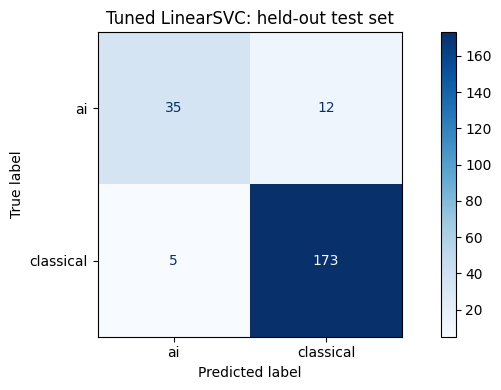

CV scores: {'MultinomialNB': np.float64(0.4944721185561683), 'LogisticRegression': np.float64(0.8336816191477692), 'LinearSVC': np.float64(0.8505479530247723), 'RandomForest': np.float64(0.8153027166333967), 'Tuned LinearSVC': np.float64(0.8505479530247723)}
Deployment selection: LinearSVC
Deployment model held-out report:
               precision    recall  f1-score   support

          ai       0.88      0.74      0.80        47
   classical       0.94      0.97      0.95       178

    accuracy                           0.92       225
   macro avg       0.91      0.86      0.88       225
weighted avg       0.92      0.92      0.92       225



In [61]:
# tune model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(
    text_pipeline(LinearSVC(class_weight='balanced', random_state=SEED)),
    param_grid={
        'tfidf__ngram_range': [(1, 1), (1, 2)],
        'tfidf__min_df': [2, 4],
        'model__C': [0.1, 1, 10],
    },
    scoring='f1_macro', cv=cv, n_jobs=1, refit=True,
)
search.fit(X_train, y_train)
print('Best cross-validation macro-F1:', round(search.best_score_, 4))
print('Best parameters:', search.best_params_)
results.append(evaluate_model('Tuned LinearSVC', search.best_estimator_))
comparison = pd.DataFrame(results).sort_values('test_macro_f1', ascending=False)
print(comparison.round(3).to_string(index=False))
print('Tuned classification report:\n', classification_report(y_test, search.predict(X_test), zero_division=0))

# evaluate results
fig, ax = plt.subplots(figsize=(8, 4))
ConfusionMatrixDisplay.from_predictions(y_test, search.predict(X_test), ax=ax, cmap='Blues')
ax.set_title('Tuned LinearSVC: held-out test set')
plt.tight_layout()
plt.savefig("../data/processed/classification_confusion_matrix.png", dpi=150)
plt.show()

# save model
# Select final deployment by training-only cross-validation, not test performance.
cv_scores = {}
from sklearn.model_selection import cross_val_score
for name, estimator in candidates.items():
    cv_scores[name] = cross_val_score(text_pipeline(clone(estimator)), X_train, y_train,
                                      cv=cv, scoring='f1_macro', n_jobs=1).mean()
cv_scores['Tuned LinearSVC'] = search.best_score_
best_name = max(cv_scores, key=cv_scores.get)
best_model = search.best_estimator_ if best_name == 'Tuned LinearSVC' else fitted[best_name]
joblib.dump(best_model,"../deployment/research_classifier.joblib")
print('CV scores:', cv_scores)
print('Deployment selection:', best_name)
print('Deployment model held-out report:\n', classification_report(y_test, best_model.predict(X_test), zero_division=0))
comparison.to_csv("../data/processed/model_comparison.csv", index=False)

### Streamlit web interface
The deployment application is in deployment/app.py.